# Numerical Exercises 2
## Excercise 2.1
- Compute the following 1D integral via Monte Carlo 
$$I = \int_0^1 \frac{\pi}{2}\cos(\pi x/2) dx = 1$$

1. sampling a uniform distribution in $[0,1]$
2. using importance sampling (i.e. sampling a non-uniform probability in $[0,1]$)

Show a picture of both your estimations of $I$ and their uncertainties with a large number of *throws* $M$ (e.g. $M\ge 10^4$) as a function of the number of blocks, $N$.

### **Solution**
### MC integration and Importance sampling

**Monte Carlo integration** is a stochastic numerical method used to estimate the value of an integral $I = \int_{\Omega} g(x)p(x) dx$ by evaluating the arithmetic mean $G_N$ over $N$ random variable samples $x_i$ drawn from the probability density function $p(x)$:

$$G_N = \frac{1}{N} \sum_{i=1}^N g(x_i)$$

The **error** of the Monte Carlo estimator converges as $\varepsilon = \frac{\sigma_I}{\sqrt{N}}$, where $\sigma_I^2 = \int_{\Omega} g^2(x)p(x) dx - I^2$ is the variance of the function. The core advantage of this method is that the computational time and its error convergence exponent are **completely independent of the dimension $d$**. As a result, for high-dimensional integrals, Monte Carlo integration becomes far more computationally efficient than traditional integration methods as standard quadrature.

**Importance sampling** is a variance reduction technique where, instead of sampling from the original probability distribution $p(x)$, samples $x_i$ are drawn from a new density distribution $d(x)$. The integral $I = \int_{\Omega} g(x)p(x) dx$ is rewritten as:

$$I = \int_{\Omega} \left[ \frac{g(x)p(x)}{d(x)} \right] d(x) dx$$
and the Monte Carlo estimator becomes:

$$G_N = \frac{1}{N} \sum_{i=1}^N \frac{g(x_i)p(x_i)}{d(x_i)}$$

The more similar $d(x)$ is to $|g(x)p(x)|$, the more variance is reduced. A good choice for our problem (one must take into account computability of che cumulative inverse) is the (normalized) first order expansion with Taylor series of our intgrand $f(x)=\frac{\pi}{2} \cos(\pi x /2)$: $$d(x)=2(1-x)$$
I expanded around $x=1$ instead od $x=0$ because this latter choice would have led to a negative PDF. 
<br>
In the following plot, I compared the solutions and the error of the integral given by two different approaches: uniform and importance sampling.

**Plot parameters**:
* $M = 10^5$ 
* $N = 10^2$
* $L = 10^3$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.optimize import curve_fit

In [10]:
blocks_m, _,mean_val, mean_err = np.loadtxt("2.1/OUTPUT/IS_int.dat", unpack=True)
blocks_v, _, var_val, var_err = np.loadtxt("2.1/OUTPUT/unif_int.dat", unpack=True)
data_discr = np.loadtxt("2.2/OUTPUT/discrRW.dat")
data_cont  = np.loadtxt("2.2/OUTPUT/contRW.dat")
data_d = np.loadtxt("2.2/OUTPUT/RW_discr_path.dat")
data_c = np.loadtxt("2.2/OUTPUT/RW_cont_path.dat")

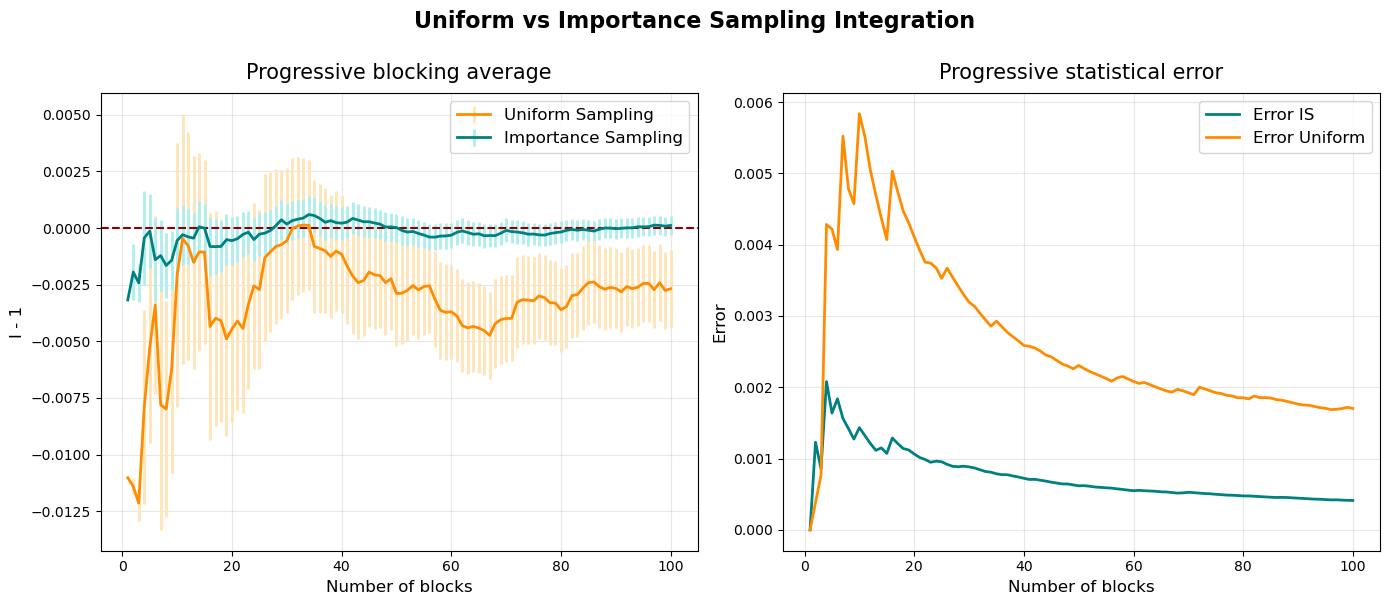

In [5]:
%matplotlib inline
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 6), tight_layout=True)
fig.suptitle("Uniform vs Importance Sampling Integration", fontsize=16, fontweight='bold', y=1)
axs[0].errorbar(blocks_v, var_val, yerr=var_err, fmt='-', 
     color='darkorange', ecolor='moccasin', 
     elinewidth=2, linewidth=2, 
     label='Uniform Sampling')

axs[0].errorbar(blocks_m, mean_val, yerr=mean_err, fmt='-', 
     color='teal', ecolor='paleturquoise', 
     elinewidth=2, linewidth=2, 
     label='Importance Sampling')

axs[0].set_title('Progressive blocking average', fontsize=15, pad=10)
axs[0].set_xlabel('Number of blocks', fontsize=12)
axs[0].set_ylabel('I - 1', fontsize=12)
axs[0].grid(True, alpha=0.3)
axs[0].axhline(y=0, color='darkred', linestyle='--', linewidth=1.5)
axs[0].legend(fontsize=12, loc='best')

axs[1].plot(blocks_m, mean_err, color='teal', linewidth=2, label='Error IS')
axs[1].plot(blocks_v, var_err, color='darkorange', linewidth=2, label='Error Uniform')
axs[1].set_title('Progressive statistical error', fontsize=15, pad=10)
axs[1].set_xlabel('Number of blocks',  fontsize=12)
axs[1].set_ylabel('Error', fontsize=12)
axs[1].grid(True, alpha=0.3)
axs[1].legend(fontsize=12, loc='best')

The plots illustrate the clear superiority of Importance Sampling over Uniform Sampling for evaluating the integral.

## Excercise 2.2
- 3D Random Walks (RW) on a cubic lattice and in the continuum: Repeat many times (e.g. say $10^4$) the simulation of a random walk in 3D always starting at the origin

1. on a cubic lattice with lattice constant $a=1$; at each discrete time the walker makes a forward or backward step of length equal to $a$ in one of the 3 principal directions of the lattice: $x$, $y$ or $z$
2. in the continuum; at each discrete time the walker makes a step of length equal to $a(=1)$ along a **random direction** obtained by sampling **uniformly** the solid angle: $\theta \in [0,\pi]$ and $\phi \in [0,2\pi]$

Show a picture of $\sqrt{\langle |\vec{r}_N|^2 \rangle_{RW}}$ for both RWs, with their statistical uncertainties, as function of the step $i\in [0,10^2]$.

Suggestion: divide your $M$ throws into a reasonable number of blocks, compute $\sqrt{\langle |\vec{r}_N|^2 \rangle_{RW}}$ as function of the step $i\in [0,10^2]$ in each block and use these values (for fixed $i$) to obtain the average value and its statistical uncertainty.

Note that you could try to fit both results with a function like $f(N)=k\sqrt{N}$. Do your results indicate a diffusive behavior?

### **Solution**

A **Random Walk (RW)** is a stochastic process describing a path made of successive random steps, which can take place in discrete or continuous spaces. Because each displacement depends only on the current state and is independent of previous steps, it is inherently a memory-less **Markov process**. Consequently, the displacement vectors $\vec{r}_{i, i+1}$ are uncorrelated for any distinct pair of steps:

$$\langle \vec{r}_{i, i+1} \cdot \vec{r}_{j, j+1} \rangle = 0 \quad \forall i \neq j$$

By virtue of the **Central Limit Theorem**, the diffusive nature of the walk emerges asymptotically, leading to a **root-mean-square displacement** scaling as the square root of the number of steps $N$:

$$\sqrt{\langle |\vec{r}|^2 \rangle} = a \sqrt{N}$$

where $a$ is the constant step length (set to $a = 1$).

In this simulation, I implemented a 3D Random Walk under two different geometric conditions: on a discrete cubic lattice and in continuous space with isotropic solid angle sampling. Using the data blocking technique over $10^5$ repetitions organized in $10^2$ blocks, I compared the simulated $\sqrt{\langle |\vec{r}_N|^2 \rangle}$ against the theoretical diffusive prediction. This confirms that the asymptotic diffusive scaling depends solely on the Markovian, uncorrelated character of the steps rather than the specific discrete or continuous geometry of the underlying space.
### Implementation 

Both simulations track the progressive root-mean-square displacement $\sqrt{\langle |\vec{r}_N|^2 \rangle}$ over $N$ steps using data blocking across $L$ walks per block:

* **Discrete 3D Lattice:** At each step, one of the three Cartesian axes is selected with uniform probability ($x, y$, or $z \in \{0, 1, 2\}$). The walker then performs a unit displacement of lattice constant $a = 1$ forward or backward ($\pm 1$) along that axis with equal probability ($p = 0.5$).
* **Continuous 3D Space:** To ensure isotropic sampling over the solid angle $d\Omega = \sin\theta\,d\theta\,d\phi$, the direction is generated by uniformly sampling the azimuthal angle $\phi \in [0, 2\pi)$ and the cosine of the polar angle $\cos\theta \in [-1, 1]$. Using $\sin\theta = \sqrt{1 - \cos^2\theta}$, the walker advances by a unit displacement vector $\Delta\vec{r} = (\sin\theta\cos\phi,\, \sin\theta\sin\phi,\, \cos\theta)$.

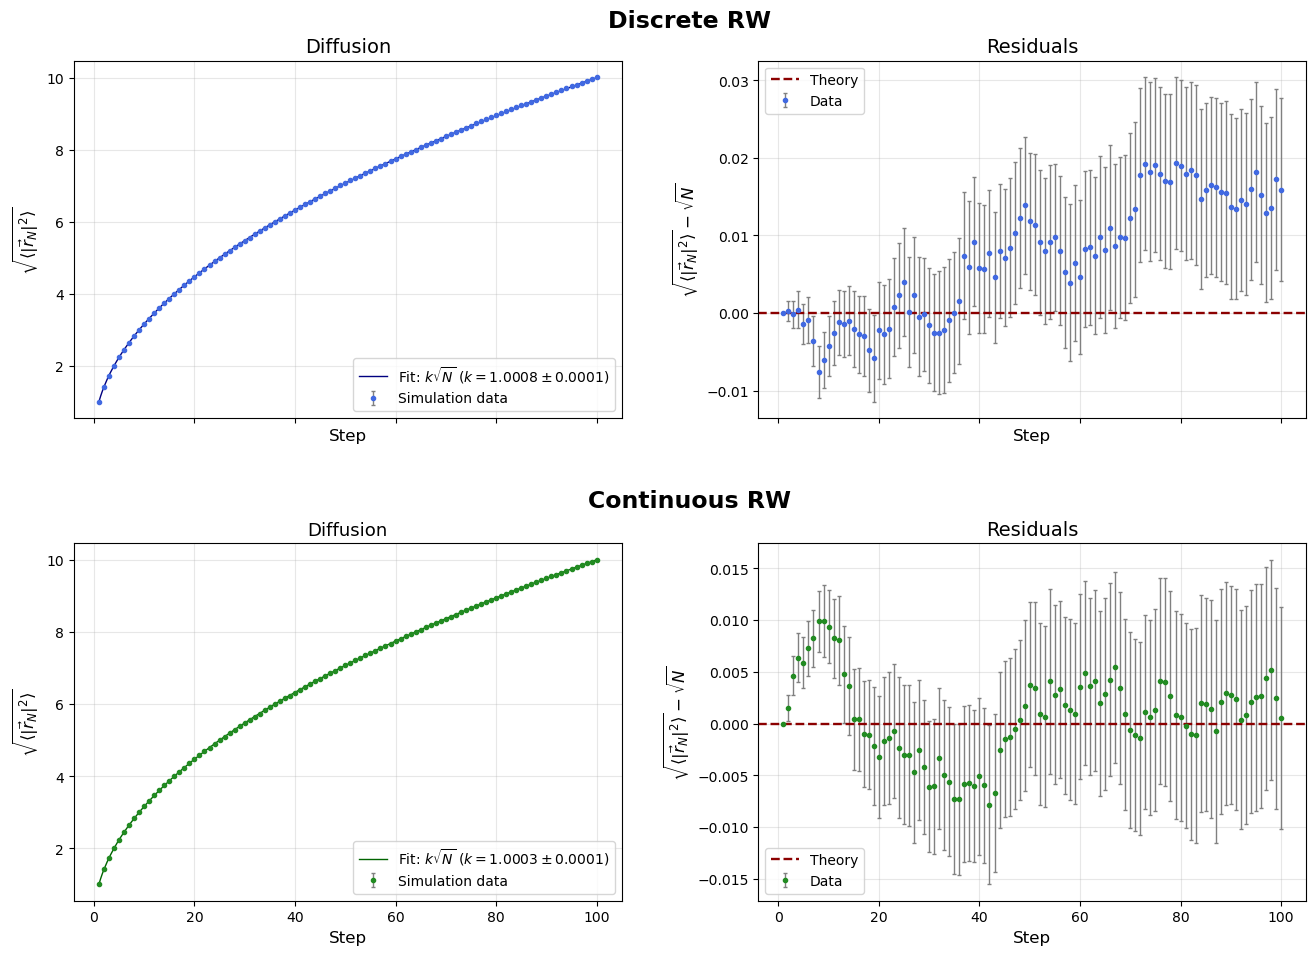

In [11]:
%matplotlib inline
def f_diff(N, k):
    return k * np.sqrt(N)

steps_d, r_d, err_d = data_discr[:, 0], data_discr[:, 1], data_discr[:, 2]
steps_c, r_c, err_c = data_cont[:, 0], data_cont[:, 1], data_cont[:, 2]

mask_d = err_d > 0.0
mask_c = err_c > 0.0

popt_d, pcov_d = curve_fit(f_diff, steps_d[mask_d], r_d[mask_d], sigma=err_d[mask_d], p0=[1.0], absolute_sigma=True)
popt_c, pcov_c = curve_fit(f_diff, steps_c[mask_c], r_c[mask_c], sigma=err_c[mask_c], p0=[1.0], absolute_sigma=True)

k_d_err = np.sqrt(np.diag(pcov_d))[0]
k_c_err = np.sqrt(np.diag(pcov_c))[0]

expected_d = 1.0 * np.sqrt(steps_d)
expected_c = 1.0 * np.sqrt(steps_c)

fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
dense_steps = np.linspace(steps_d[0], steps_d[-1], 300)

# --- RIGA 1: DISCRETE RW ---
axs[0, 0].errorbar(steps_d, r_d, yerr=err_d, fmt='o', markersize=3, color='royalblue', ecolor='gray', elinewidth=1, capsize=1.5, label='Simulation data')
axs[0, 0].plot(dense_steps, f_diff(dense_steps, *popt_d), color='navy', lw=1, label=f'Fit: $k\\sqrt{{N}}$ ($k = {popt_d[0]:.4f} \\pm {k_d_err:.4f}$)')
axs[0, 0].set_xlabel('Step', fontsize=12)
axs[0, 0].set_ylabel(r'$\sqrt{\langle |\vec{r}_N|^2 \rangle}$', fontsize=12)
axs[0, 0].set_title('Diffusion', fontsize=14)
axs[0, 0].grid(True, alpha=0.3)
axs[0, 0].legend(loc='lower right', frameon=True)

res_d = r_d - expected_d
axs[0, 1].errorbar(steps_d, res_d, yerr=err_d, fmt='o', markersize=3, 
                   color='royalblue', ecolor='gray', elinewidth=1, capsize=1.5, label=r'Data')
axs[0, 1].axhline(0.0, color='darkred', linestyle='--', lw=1.7, label='Theory')
axs[0, 1].set_xlabel('Step', fontsize=12)
axs[0, 1].set_ylabel(r'$\sqrt{\langle |\vec{r}_N|^2 \rangle} - \sqrt{N}$', fontsize=12)
axs[0, 1].set_title('Residuals', fontsize=14)
axs[0, 1].grid(True, alpha=0.3)
axs[0, 1].legend(loc='best', frameon=True)

# --- RIGA 2: CONTINUOUS RW ---
axs[1, 0].errorbar(steps_c, r_c, yerr=err_c, fmt='o', markersize=3, 
                   color='forestgreen', ecolor='gray', elinewidth=1, capsize=1.5, label='Simulation data')
axs[1, 0].plot(dense_steps, f_diff(dense_steps, *popt_c), color='darkgreen', lw=1, 
               label=f'Fit: $k\\sqrt{{N}}$ ($k = {popt_c[0]:.4f} \\pm {k_c_err:.4f}$)')
axs[1, 0].set_xlabel('Step', fontsize=12)
axs[1, 0].set_ylabel(r'$\sqrt{\langle |\vec{r}_N|^2 \rangle}$', fontsize=12)
axs[1, 0].set_title('Diffusion', fontsize=13)
axs[1, 0].grid(True, alpha=0.3)
axs[1, 0].legend(loc='lower right', frameon=True)

res_c = r_c - expected_c
axs[1, 1].errorbar(steps_c, res_c, yerr=err_c, fmt='o', markersize=3, 
                   color='forestgreen', ecolor='gray', elinewidth=1, capsize=1.5, label='Data')
axs[1, 1].axhline(0.0, color='darkred', linestyle='--', lw=1.7, label='Theory')
axs[1, 1].set_xlabel('Step', fontsize=12)
axs[1, 1].set_ylabel(r'$\sqrt{\langle |\vec{r}_N|^2 \rangle} - \sqrt{N}$', fontsize=12)
axs[1, 1].set_title('Residuals', fontsize=14)
axs[1, 1].grid(True, alpha=0.3)
axs[1, 1].legend(loc='best', frameon=True)

fig.subplots_adjust(left=0.08, right=0.96, bottom=0.08, top=0.92, hspace=0.35, wspace=0.25)

fig.text(0.52, 0.96, "Discrete RW", fontsize=17, fontweight='bold', ha='center', va='center')
fig.text(0.52, 0.48, "Continuous RW", fontsize=17, fontweight='bold', ha='center', va='center')

plt.show()
plt.close(fig)


The left panels illustrate the root-mean-square displacement as a function of the number of steps $N$, fitted with the diffusive power law $f(N) = k\sqrt{N}$. The fitting procedure yields $k = 1.0008 \pm 0.0001$ for the discrete Random Walk and $k = 1.0003 \pm 0.0001$ for the continuous one. At first glance, these values might appear statistically incompatible with the exact theoretical expectation of $k = 1$. However, to correctly evaluate the goodness of the simulation, we must analyze the residual plots on the right, which show the difference between the simulated data and the exact theoretical curve ($\sqrt{N}$). In these panels, the error bars represent the true statistical uncertainty at each step, rigorously computed via the data blocking method. As clearly shown, the theoretical expectation (the dashed red line at $y = 0$) falls well within the error bars for almost all the simulated steps in both spatial configurations. 

This confirms an excellent agreement between the simulation and the theoretical model, proving that the implemented Random Walk correctly reproduces the expected diffusive behavior once the statistical correlations are properly taken into account. It is also clear that the behaviour of the displacement it's the same in both discrete and continuous. In the next tool, there's an interactive 3D visual representation of two of the trajectories (discrete and continuous) to give a visual idea of this fact. 

In [7]:
%matplotlib widget
fig = go.Figure()

# Traiettoria discreta
fig.add_trace(go.Scatter3d(
    x=data_d[:, 0], y=data_d[:, 1], z=data_d[:, 2],
    mode='lines+markers',
    marker=dict(size=2),
    line=dict(color='royalblue', width=3),
    name='Discrete'
))

# Traiettoria continua
fig.add_trace(go.Scatter3d(
    x=data_c[:, 0], y=data_c[:, 1], z=data_c[:, 2],
    mode='lines+markers',
    marker=dict(size=2),
    line=dict(color='crimson', width=3),
    name='Continuous'
))

fig.update_layout(
    title='Random Walk 3D',
    scene=dict(xaxis_title='X', yaxis_title='Y', zaxis_title='Z'),
    margin=dict(l=0, r=0, b=0, t=30)
)

fig.show()